In [341]:
import cv2
import numpy as np

image = "../data/labeled/images/A-7_default_mmrsbpb_mMRS-BPB_15122023132129.jpg"

circle_mask = (
    "../data/labeled/circle_masks/A-7_default_mmrsbpb_mMRS-BPB_15122023132129.png"
)

colony_mask = "../data/labeled/masks/A-7_default_mmrsbpb_mMRS-BPB_15122023132129.png"

image = cv2.imread(image)
circle_mask = cv2.imread(circle_mask, cv2.IMREAD_GRAYSCALE)
colony_mask = cv2.imread(colony_mask, cv2.IMREAD_GRAYSCALE)

circle_mask = np.where(circle_mask > 0, 1, 0)
colony_mask = np.where(colony_mask > 0, 1, 0)

np.unique(circle_mask)

array([0, 1])

In [342]:
def check_circle(center, radius):
    proposed_circle_filled = np.zeros_like(circle_mask, dtype=np.uint8)
    cv2.circle(proposed_circle_filled, center, radius, 1, -1)
    overlap = np.sum(np.logical_and(proposed_circle_filled, circle_mask))
    proposed_circle_sum = np.sum(proposed_circle_filled)

    inside_area = overlap == proposed_circle_sum

    overlap = np.sum(np.logical_and(proposed_circle_filled, colony_mask))

    has_colonies = overlap > 0

    proposed_circle_outlined = np.zeros_like(circle_mask, dtype=np.uint8)
    cv2.circle(proposed_circle_outlined, center, radius + 10, 1, 12)
    overlap = np.sum(np.logical_and(proposed_circle_outlined, colony_mask))

    no_colony_overlap = overlap == 0

    return inside_area and no_colony_overlap and has_colonies

In [343]:
def generate_random_circle():
    center = np.random.randint(0, circle_mask.shape[0], 2)
    radius = np.random.randint(circle_mask.shape[0] // 36, circle_mask.shape[0] // 12)

    return center, radius

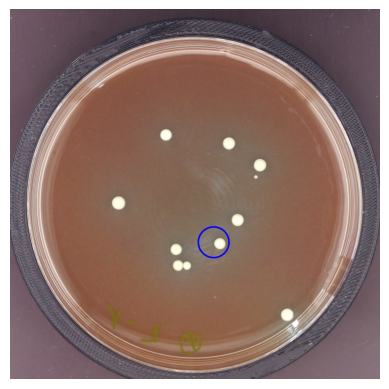

Found on try  5


In [344]:
import matplotlib.pyplot as plt

for i in range(10000):
    # Draw random circle and show it as an image
    center, radius = generate_random_circle()

    check = check_circle(center, radius)

    if check:

        new_image = np.copy(image)

        cv2.circle(new_image, center, radius + 10, (0, 0, 255), 12)

        plt.imshow(new_image)
        plt.axis("off")
        plt.show()

        print("Found on try ", i)
        break